<a href="https://colab.research.google.com/github/miriamamin1213-ux/3-Fold/blob/main/HancockGPT2L4BFSHAP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# HANCOCK GPT-2 Last 4 Block Unfrozen
# ============================================================
# 1. IMPORT LIBRARIES, SET SEEDS AND SELECT DEVICE
# ============================================================
import os, random, json, gdown
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, balanced_accuracy_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

SEED = 42

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ============================================================
# 2. LOAD AND MERGE HANCOCK CLINICAL/PATHOLOGICAL DATA
# ============================================================
CLINICAL_FILE = "clinical_data.json"
PATHOLOGICAL_FILE = "pathological_data.json"

if not os.path.exists(CLINICAL_FILE):
    if gdown.download(
        id="1F_kngwHn6KkOQqSwtYXCaF-bT8DZt__Q",
        output=CLINICAL_FILE, quiet=False
    ) is None:
        raise FileNotFoundError("Could not download clinical_data.json.")

if not os.path.exists(PATHOLOGICAL_FILE):
    if gdown.download(
        id="1KY3NS9q3lfodf-t3g92S1JE3Vqcl6o3F",
        output=PATHOLOGICAL_FILE, quiet=False
    ) is None:
        raise FileNotFoundError("Could not download pathological_data.json.")

def load_json_table(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)
    if isinstance(obj, list):
        return pd.DataFrame(obj)
    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if key in obj and isinstance(obj[key], list):
                return pd.DataFrame(obj[key])
        try:
            return pd.DataFrame(obj)
        except ValueError:
            pass
    raise ValueError(f"Could not convert {path} to a table.")

clinical_df = load_json_table(CLINICAL_FILE)
pathological_df = load_json_table(PATHOLOGICAL_FILE)
if ("patient_id" not in clinical_df.columns or
        "patient_id" not in pathological_df.columns):
    raise KeyError("Both JSON files must contain 'patient_id'.")

df = clinical_df.merge(
    pathological_df, on="patient_id", how="left",
    suffixes=("", "_path")
)
print("Clinical shape:", clinical_df.shape)
print("Pathology shape:", pathological_df.shape)
print("Merged shape:", df.shape)

# ============================================================
# 3. SELECT SIX FEATURES AND DEFINE THE HPV TARGET
# ============================================================
def resolve_col(candidates, required=False):
    for c in candidates:
        if c in df.columns:
            return c
    if required:
        raise KeyError(
            f"Required column not found: {candidates}. "
            f"Available columns: {df.columns.tolist()}"
        )
    return None

target_col = resolve_col(
    ["hpv_association_p16", "hpv_association_p16_path"],
    required=True
)
feature_candidates = {
    "age_at_initial_diagnosis": [
        "age_at_initial_diagnosis", "age_at_initial_diagnosis_path"
    ],
    "sex": ["sex", "sex_path"],
    "smoking_status": ["smoking_status", "smoking_status_path"],
    "primary_tumor_site": [
        "primary_tumor_site", "primary_tumor_site_path"
    ],
    "primarily_metastasis": [
        "primarily_metastasis", "primarily_metastasis_path"
    ],
    "pN_stage": [
        "pN_stage", "pN_stage_path",
        "pathological_N_stage", "pathological_n_stage"
    ]
}
feature_map = {
    name: resolve_col(cols, required=True)
    for name, cols in feature_candidates.items()
}
features = list(feature_candidates.keys())
df = df.dropna(subset=[target_col]).copy()

def normalize_target(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in ["negative", "neg", "0", "false", "no"]:
        return 0
    if s in ["positive", "pos", "1", "true", "yes"]:
        return 1
    try:
        n = float(s)
        if n in [0, 1]:
            return int(n)
    except ValueError:
        pass
    return np.nan

df["HPV_Label"] = df[target_col].apply(normalize_target)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
feature_df = df[[feature_map[c] for c in features]].copy()
feature_df = feature_df.rename(
    columns={feature_map[c]: c for c in features}
)
df = pd.concat([feature_df, df[["HPV_Label"]]], axis=1)
df = df.loc[:, ~df.columns.duplicated()].copy()
df["age_at_initial_diagnosis"] = pd.to_numeric(
    df["age_at_initial_diagnosis"], errors="coerce"
)
print("Patients:", len(df))
print("HPV classes (0=negative, 1=positive):")
print(df["HPV_Label"].value_counts().sort_index())
print("Features:", features)
print("N-stage source:", feature_map["pN_stage"])

# ============================================================
# 4. STRATIFIED TRAIN/VALIDATION/TEST SPLIT (65/15/20)
# ============================================================
train_val_df, test_df = train_test_split(
    df, test_size=0.20, random_state=SEED,
    stratify=df["HPV_Label"]
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1875, random_state=SEED,
    stratify=train_val_df["HPV_Label"]
)
train_df, val_df, test_df = (
    split.copy() for split in [train_df, val_df, test_df]
)

# ============================================================
# 5. IMPUTE MISSING VALUES USING TRAINING DATA ONLY
# ============================================================
fill_values = {}
for c in features:
    if pd.api.types.is_numeric_dtype(train_df[c]):
        value = train_df[c].median()
        if pd.isna(value):
            value = 0
    else:
        modes = train_df[c].dropna().astype(str).mode()
        value = modes.iloc[0] if not modes.empty else "Unknown"
    fill_values[c] = value
    for split in [train_df, val_df, test_df]:
        split[c] = split[c].fillna(value)
        if split[c].dtype == object:
            split[c] = split[c].astype(str).replace({
                "": "Unknown", "nan": "Unknown", "None": "Unknown"
            })

y_train = train_df["HPV_Label"].to_numpy(dtype=int)
y_val = val_df["HPV_Label"].to_numpy(dtype=int)
y_test = test_df["HPV_Label"].to_numpy(dtype=int)
print("Train:", len(train_df), np.bincount(y_train, minlength=2))
print("Validation:", len(val_df), np.bincount(y_val, minlength=2))
print("Test:", len(test_df), np.bincount(y_test, minlength=2))

# ============================================================
# 6. CONVERT EXACTLY SIX CLINICAL FEATURES INTO TEXT
# ============================================================

def display_value(x):
    if pd.isna(x):
        return "Unknown"

    if isinstance(x, (float, np.floating)) and float(x).is_integer():
        return str(int(x))

    return str(x).strip()


def patient_to_text(row):

    # Feature 1: Age
    age = display_value(row["age_at_initial_diagnosis"])

    # Feature 2: Sex
    sex_value = str(row["sex"]).strip().lower()

    if sex_value in ["1", "male", "m"]:
        sex = "male"
    elif sex_value in ["0", "female", "f"]:
        sex = "female"
    else:
        sex = display_value(row["sex"])

    # Feature 3: Smoking status
    smoking_value = str(row["smoking_status"]).strip().lower()

    if smoking_value in ["0", "non-smoker", "nonsmoker", "never"]:
        smoking = "a non-smoker"
    elif smoking_value in ["1", "smoker", "current smoker", "yes"]:
        smoking = "a smoker"
    else:
        smoking = display_value(row["smoking_status"])

    # Feature 4: Primary tumour site
    site = display_value(row["primary_tumor_site"])

    # Feature 5: Primarily metastasis
    metastasis = display_value(row["primarily_metastasis"])

    # Feature 6: Pathological N stage
    n_stage = display_value(row["pN_stage"])

    prompt = (
        "Q: Predict this patient's Human Papillomavirus (HPV) status "
        "using the clinical information available. "

        f"This patient is {age} years old and is {sex}. "
        f"The patient is {smoking}. "
        f"The primary tumour site is {site}. "
        f"The primarily metastasis status is {metastasis}. "
        f"Pathological nodal stage is {n_stage}. "

        "Based on these six clinical features, "
        "predict whether the patient is HPV positive or HPV negative. "
        "Answer with only Yes or No.\nA:"
    )

    return prompt


# Verify exactly six input features
features = [
    "age_at_initial_diagnosis",
    "sex",
    "smoking_status",
    "primary_tumor_site",
    "primarily_metastasis",
    "pN_stage"
]

assert len(features) == 6

print("Number of clinical features:", len(features))
print("Features:", features)

print("\nExample clinical prompt:")
print(patient_to_text(df.iloc[0]))
# ============================================================
# 7. LOAD TOKENIZER AND SELECT MAXIMUM LENGTH
# ============================================================
MODEL_NAME = "openai-community/gpt2"
tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

# Determine the length policy from training prompts only to avoid
# using validation/test data to choose preprocessing parameters.

# Generate clinical text prompts for each dataset split
train_texts = [
    patient_to_text(row)
    for _, row in train_df.iterrows()
]

val_texts = [
    patient_to_text(row)
    for _, row in val_df.iterrows()
]

test_texts = [
    patient_to_text(row)
    for _, row in test_df.iterrows()
]

print("Training prompts:", len(train_texts))
print("Validation prompts:", len(val_texts))
print("Test prompts:", len(test_texts))

TRAIN_PROMPT_LENGTHS = [
    len(tokenizer.encode(t, add_special_tokens=False))
    for t in train_texts
]
print("Training prompt tokens: min =", min(TRAIN_PROMPT_LENGTHS),
      "| median =", int(np.median(TRAIN_PROMPT_LENGTHS)),
      "| 95th percentile =", int(np.percentile(TRAIN_PROMPT_LENGTHS, 95)),
      "| max =", max(TRAIN_PROMPT_LENGTHS))
MAX_LENGTH = min(
    1024, max(32, int(np.ceil(max(TRAIN_PROMPT_LENGTHS) / 8) * 8))
)
if max(TRAIN_PROMPT_LENGTHS) > 1024:
    print("WARNING: Some training prompts exceed GPT-2's context limit.")
print("Selected MAX_LENGTH:", MAX_LENGTH)

BATCH_SIZE = 64
EPOCHS = 500
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1
print("Batch size:", BATCH_SIZE, "| Epochs:", EPOCHS,
      "| Learning rate:", LEARNING_RATE,
      "| Weight decay:", WEIGHT_DECAY)

# ============================================================
# 8. BUILD DATASETS AND DATA LOADERS
# ============================================================
class HPVTextDataset(Dataset):
    def __init__(self, texts, labels):
        self.items = []
        for text, label in zip(texts, labels):
            encoded = tokenizer(
                text, max_length=MAX_LENGTH, padding="max_length",
                truncation=True, return_tensors="pt"
            )
            self.items.append((
                encoded["input_ids"].squeeze(0),
                encoded["attention_mask"].squeeze(0), int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        input_ids, attention_mask, label = self.items[index]
        return {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "label": torch.tensor(label, dtype=torch.long)
        }

train_dataset = HPVTextDataset(train_texts, y_train)
val_dataset = HPVTextDataset(val_texts, y_val)
test_dataset = HPVTextDataset(test_texts, y_test)
train_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=train_generator, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

# ============================================================
# 9. INITIALISE GPT-2 CLASSIFIER AND CLASS WEIGHTS
# ============================================================
c
# 9. INITIALISE GPT-2 CLASSIFIER AND CLASS-WEIGHTED LOSS

class HPVNetGPT2Text(nn.Module):
    def __init__(self, model_name=MODEL_NAME, num_classes=2,
                 dropout=DROPOUT):
        super().__init__()
        self.gpt2 = GPT2Model.from_pretrained(model_name)
        self.gpt2.config.use_cache = False
        self.gpt2.config.pad_token_id = tokenizer.pad_token_id
        hidden_size = self.gpt2.config.hidden_size
        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.gpt2(
            input_ids=input_ids,
            attention_mask=attention_mask,
            use_cache=False,
            return_dict=True
        )
        hidden_states = outputs.last_hidden_state
        last_positions = attention_mask.sum(dim=1) - 1
        pooled_output = hidden_states[
            torch.arange(hidden_states.size(0), device=hidden_states.device),
            last_positions
        ]
        return self.classifier(pooled_output)


model = HPVNetGPT2Text().to(device)

# Freeze the GPT-2 backbone, then unfreeze only the final four blocks.
for param in model.gpt2.parameters():
    param.requires_grad = False

for block in model.gpt2.h[-4:]:
    for param in block.parameters():
        param.requires_grad = True

# Keep the classifier head trainable.
for param in model.classifier.parameters():
    param.requires_grad = True

# Verify trainable parameters.
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
total_params = sum(p.numel() for p in model.parameters())

print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")
print("Trainable GPT-2 blocks: final 4 only; classifier head: trainable")

# Calculate class weights.
class_counts = np.bincount(y_train, minlength=2)
class_weights = torch.tensor(
    len(y_train) / (2 * np.maximum(class_counts, 1)),
    dtype=torch.float32,
    device=device
)

print(
    "Class weights [negative, positive]:",
    class_weights.detach().cpu().numpy()
)

def weighted_classification_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits, labels, reduction="none"
    )
    return (losses * class_weights[labels]).mean()

# Optimise only trainable parameters.
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ============================================================
# 10. HPV SCORES, VALIDATION LOSS AND THRESHOLD SELECTION
# ============================================================
def get_hpv_scores(loader):
    model.eval()
    scores, labels_all = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            logits = model(input_ids=input_ids,
                           attention_mask=attention_mask)
            scores.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            labels_all.extend(batch["label"].numpy())
    return np.asarray(scores, dtype=float), np.asarray(labels_all, dtype=int)

def evaluate_loss(loader):
    model.eval()
    total_loss, total_examples = 0.0, 0
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)
            logits = model(input_ids=input_ids,
                           attention_mask=attention_mask)
            loss = weighted_classification_loss(logits, labels)
            n = labels.size(0)
            total_loss += loss.item() * n
            total_examples += n
    return total_loss / max(total_examples, 1)

def select_threshold(scores, labels):
    thresholds = np.unique(np.concatenate(([0.0], scores, [1.0])))
    results = [
        (float(t), balanced_accuracy_score(labels, (scores >= t).astype(int)))
        for t in thresholds
    ]
    # Maximise balanced accuracy; ties go to the threshold closest to 0.5.
    return max(results, key=lambda x: (x[1], -abs(x[0] - 0.5)))

# ============================================================
# 11. TRAIN AND SAVE BEST VALIDATION CHECKPOINTS
# ============================================================
OUT_DIR = Path("ROC_HANCOCK_GPT2_CLASSIFIER")
OUT_DIR.mkdir(parents=True, exist_ok=True)
checkpoint_paths = {
    "Validation_Loss": OUT_DIR / "best_model_validation_loss.pth",
    "Validation_ROC_AUC": OUT_DIR / "best_model_validation_roc_auc.pth",
    "Validation_PR_AUC": OUT_DIR / "best_model_validation_pr_auc.pth",
    "Validation_Balanced_Accuracy":
        OUT_DIR / "best_model_validation_balanced_accuracy.pth"
}
best = {
    "Validation_Loss": {
        "value": float("inf"), "epoch": None, "threshold": None
    },
    "Validation_ROC_AUC": {
        "value": -float("inf"), "epoch": None, "threshold": None
    },
    "Validation_PR_AUC": {
        "value": -float("inf"), "epoch": None, "threshold": None
    },
    "Validation_Balanced_Accuracy": {
        "value": -float("inf"), "epoch": None, "threshold": None
    }
}
history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss_sum, train_examples = 0.0, 0
    for batch in train_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(input_ids=input_ids, attention_mask=attention_mask)
        loss = weighted_classification_loss(logits, labels)
        loss.backward()
        optimizer.step()
        n = labels.size(0)
        train_loss_sum += loss.item() * n
        train_examples += n

    train_loss = train_loss_sum / max(train_examples, 1)
    val_loss = evaluate_loss(val_loader)
    val_scores, val_labels = get_hpv_scores(val_loader)
    val_auc = roc_auc_score(val_labels, val_scores)
    val_ap = average_precision_score(val_labels, val_scores)
    val_threshold, val_ba = select_threshold(val_scores, val_labels)
    history.append({
        "Epoch": epoch, "Train_Loss": train_loss,
        "Validation_Loss": val_loss, "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_ap,
        "Validation_Balanced_Accuracy": val_ba,
        "Validation_Threshold": val_threshold
    })
    metrics = {
        "Validation_Loss": val_loss, "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_ap,
        "Validation_Balanced_Accuracy": val_ba
    }
    for metric, value in metrics.items():
        improved = (
            value < best[metric]["value"] if metric == "Validation_Loss"
            else value > best[metric]["value"]
        )
        if improved:
            best[metric] = {
                "value": float(value), "epoch": epoch,
                "threshold": float(val_threshold)
            }
            torch.save(model.state_dict(), checkpoint_paths[metric])

    if epoch % 50 == 0:
        print(
            f"Epoch {epoch}/{EPOCHS} | Train Loss={train_loss:.4f} | "
            f"Val Loss={val_loss:.4f} | Val ROC-AUC={val_auc:.4f} | "
            f"Val PR-AUC={val_ap:.4f} | Val BA={val_ba:.4f} | "
            f"Threshold={val_threshold:.6f}"
        )

pd.DataFrame(history).to_csv(OUT_DIR / "training_history.csv", index=False)
best_summary = pd.DataFrame([
    {
        "Checkpoint_Selected_By": metric, "Best_Epoch": info["epoch"],
        "Best_Validation_Metric": info["value"],
        "Threshold_Selected_On_Validation": info["threshold"],
        "Checkpoint_Path": str(checkpoint_paths[metric])
    }
    for metric, info in best.items()
])
best_summary.to_csv(
    OUT_DIR / "best_validation_checkpoints.csv", index=False
)
print("\nBEST VALIDATION CHECKPOINTS\n", best_summary.to_string(index=False))

# ============================================================
# 12. EVALUATE CHECKPOINTS ON THE HELD-OUT TEST SET
# ============================================================
test_results, test_predictions = [], {}
for metric, path in checkpoint_paths.items():
    print(f"\n===== CHECKPOINT: {metric} =====")
    model.load_state_dict(torch.load(path, map_location=device))
    scores, labels = get_hpv_scores(test_loader)
    threshold = best[metric]["threshold"]
    predictions = (scores >= threshold).astype(int)
    auc = roc_auc_score(labels, scores)
    ap = average_precision_score(labels, scores)
    ba = balanced_accuracy_score(labels, predictions)
    f1 = f1_score(labels, predictions, zero_division=0)
    cm = confusion_matrix(labels, predictions, labels=[0, 1])
    print("Best epoch:", best[metric]["epoch"])
    print(f"Validation threshold: {threshold:.6f}")
    print(classification_report(
        labels, predictions, labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"],
        digits=4, zero_division=0
    ))
    print(
        f"Test ROC-AUC: {auc:.4f} | Test PR-AUC (AP): {ap:.4f} | "
        f"Test Balanced Accuracy: {ba:.4f} | F1: {f1:.4f}"
    )
    print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)
    test_results.append({
        "Dataset": "HANCOCK", "Model": "GPT-2 Classifier",
        "Checkpoint_Selected_By": metric,
        "Best_Epoch": best[metric]["epoch"],
        "Best_Validation_Metric": best[metric]["value"],
        "Threshold_Selected_On_Validation": threshold,
        "Test_ROC_AUC": auc, "Test_PR_AUC_Average_Precision": ap,
        "Test_Balanced_Accuracy": ba, "Test_F1": f1,
        "TN": int(cm[0, 0]), "FP": int(cm[0, 1]),
        "FN": int(cm[1, 0]), "TP": int(cm[1, 1])
    })
    test_predictions[metric] = {
        "scores": scores, "predictions": predictions,
        "labels": labels, "threshold": threshold
    }
    pd.DataFrame({
        "True_Label": labels, "HPV_Positive_Score": scores,
        "Predicted_Label": predictions, "Threshold": threshold
    }).to_csv(OUT_DIR / f"test_predictions_{metric.lower()}.csv", index=False)

results_df = pd.DataFrame(test_results)
results_df.to_csv(OUT_DIR / "test_metrics_by_checkpoint.csv", index=False)
print("\nTEST RESULTS BY CHECKPOINT\n", results_df.to_string(index=False))

# ============================================================
# 13. SAVE ROC AND PRECISION-RECALL CURVES FOR ALL CHECKPOINTS
# ============================================================
for metric, result in test_predictions.items():
    labels, scores = result["labels"], result["scores"]
    auc = roc_auc_score(labels, scores)
    ap = average_precision_score(labels, scores)
    fpr, tpr, roc_thresholds = roc_curve(labels, scores)
    precision, recall, _ = precision_recall_curve(labels, scores)
    safe_name = metric.lower()
    pd.DataFrame({
        "FPR": fpr, "TPR": tpr, "Threshold": roc_thresholds
    }).to_csv(OUT_DIR / f"roc_coordinates_{safe_name}.csv", index=False)
    pd.DataFrame({
        "Precision": precision, "Recall": recall
    }).to_csv(
        OUT_DIR / f"precision_recall_coordinates_{safe_name}.csv",
        index=False
    )
    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, linewidth=2, label=f"ROC-AUC = {auc:.4f}")
    plt.plot([0, 1], [0, 1], "--", linewidth=1.5, label="Random")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"HANCOCK GPT-2 Classifier ROC: {metric}")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        OUT_DIR / f"roc_curve_{safe_name}.png",
        dpi=300, bbox_inches="tight"
    )
    plt.close()

    plt.figure(figsize=(7, 6))
    plt.plot(recall, precision, linewidth=2, label=f"PR-AUC (AP) = {ap:.4f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"HANCOCK GPT-2 Classifier Precision-Recall: {metric}")
    plt.legend(loc="lower left")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        OUT_DIR / f"precision_recall_curve_{safe_name}.png",
        dpi=300, bbox_inches="tight"
    )
    plt.close()

# ============================================================
# 14. SAVE SETTINGS AND APPEND RESULTS TO COMPARISON CSV
# ============================================================
settings = {
    "Dataset": "HANCOCK", "Model": MODEL_NAME,
    "Model_Type": "GPT-2 Classifier",
    "Features": ", ".join(features), "Number_of_Features": len(features),
    "Target": target_col, "Positive_Class": 1,
    "Positive_Class_Name": "HPV Positive",
    "Learning_Rate": LEARNING_RATE, "Weight_Decay": WEIGHT_DECAY,
    "Optimizer": "AdamW", "Epochs": EPOCHS, "Batch_Size": BATCH_SIZE,
    "Max_Length": MAX_LENGTH,
    "Max_Length_Method": (
        "Training prompts only; rounded to multiple of 8; capped at 1024"
    ),
    "Random_Seed": SEED, "Train_Validation_Test_Split": "65/15/20 stratified",
    "SMOTE": False, "Gradient_Clipping": False,
    "GPT2_Backbone_Frozen": False,
    "GPT2_Trainable_Blocks": 4,
    "Dropout": DROPOUT,
    "Class_Weights": str(class_weights.detach().cpu().numpy().tolist()),
    "Checkpoint_Selection": (
        "Best validation loss, ROC-AUC, PR-AUC and balanced accuracy"
    ),
    "Threshold_Selection": (
        "Maximise validation balanced accuracy; ties closest to 0.5"
    ),
    "HPV_Positive_Score": "Softmax probability for class 1 (HPV positive)",
    "Curves": (
        "Test ROC and precision-recall curves saved for each checkpoint"
    )
}
pd.DataFrame([settings]).to_csv(OUT_DIR / "settings.csv", index=False)

comparison_file = Path("model_roc_pr_auc_comparison.csv")
comparison_rows = results_df[[
    "Dataset", "Model", "Checkpoint_Selected_By", "Best_Epoch",
    "Test_ROC_AUC", "Test_PR_AUC_Average_Precision",
    "Test_Balanced_Accuracy", "Test_F1"
]].rename(columns={"Test_PR_AUC_Average_Precision": "Test_PR_AUC"})

if comparison_file.exists():
    existing = pd.read_csv(comparison_file)
    for col in comparison_rows.columns:
        if col not in existing.columns:
            existing[col] = np.nan
    for col in existing.columns:
        if col not in comparison_rows.columns:
            comparison_rows[col] = np.nan
    combined = pd.concat(
        [existing, comparison_rows[existing.columns]], ignore_index=True
    )
    combined = combined.drop_duplicates(
        subset=["Dataset", "Model", "Checkpoint_Selected_By"], keep="last"
    )
else:
    combined = comparison_rows

combined.to_csv(comparison_file, index=False)
print("\nSaved classifier outputs to:", OUT_DIR.resolve())
print("AUC comparison file:", comparison_file.resolve())

Device: cuda


Downloading...
From: https://drive.google.com/uc?id=1F_kngwHn6KkOQqSwtYXCaF-bT8DZt__Q
To: /content/clinical_data.json
100%|██████████| 810k/810k [00:00<00:00, 11.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=1KY3NS9q3lfodf-t3g92S1JE3Vqcl6o3F
To: /content/pathological_data.json
100%|██████████| 458k/458k [00:00<00:00, 7.89MB/s]


Clinical shape: (763, 32)
Pathology shape: (763, 18)
Merged shape: (763, 49)
Patients: 332
HPV classes (0=negative, 1=positive):
HPV_Label
0    191
1    141
Name: count, dtype: int64
Features: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']
N-stage source: pN_stage
Train: 215 [123  92]
Validation: 50 [29 21]
Test: 67 [39 28]
Number of clinical features: 6
Features: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']

Example clinical prompt:
Q: Predict this patient's Human Papillomavirus (HPV) status using the clinical information available. This patient is 60 years old and is male. The patient is a non-smoker. The primary tumour site is Oropharynx. The primarily metastasis status is no. Pathological nodal stage is pN1. Based on these six clinical features, predict whether the patient is HPV positive or HPV negative. Answer with only Yes or No.
A:


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

... (5 outputs left out)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Trainable parameters: 28,451,714 / 124,540,034
Trainable GPT-2 blocks: final 4 only; classifier head: trainable
Class weights [negative, positive]: [0.87398374 1.1684783 ]


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 50/500 | Train Loss=0.6646 | Val Loss=0.6679 | Val ROC-AUC=0.7069 | Val PR-AUC=0.5898 | Val BA=0.6929 | Threshold=0.646598
Epoch 100/500 | Train Loss=0.6329 | Val Loss=0.6360 | Val ROC-AUC=0.6987 | Val PR-AUC=0.6039 | Val BA=0.7061 | Threshold=0.415692
Epoch 150/500 | Train Loss=0.6393 | Val Loss=0.6737 | Val ROC-AUC=0.5394 | Val PR-AUC=0.4783 | Val BA=0.6486 | Threshold=0.154931
Epoch 200/500 | Train Loss=0.5325 | Val Loss=0.5508 | Val ROC-AUC=0.7923 | Val PR-AUC=0.7939 | Val BA=0.7906 | Threshold=0.342367
Epoch 250/500 | Train Loss=0.5140 | Val Loss=0.6863 | Val ROC-AUC=0.6724 | Val PR-AUC=0.7176 | Val BA=0.7143 | Threshold=0.855551
Epoch 300/500 | Train Loss=0.4611 | Val Loss=0.6065 | Val ROC-AUC=0.6954 | Val PR-AUC=0.7250 | Val BA=0.7036 | Threshold=0.437949
Epoch 350/500 | Train Loss=0.5168 | Val Loss=0.5766 | Val ROC-AUC=0.7956 | Val PR-AUC=0.7698 | Val BA=0.7578 | Threshold=0.526646
Epoch 400/500 | Train Loss=0.5041 | Val Loss=0.6392 | Val ROC-AUC=0.6724 | Val PR-AUC=0.662

In [5]:
import numpy as np
import torch
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

# Load the epoch 387 checkpoint
checkpoint_path = (
    "/content/ROC_HANCOCK_GPT2_CLASSIFIER/"
    "best_model_validation_balanced_accuracy.pth"
)

checkpoint = torch.load(checkpoint_path, map_location=device)

# Handle either a raw state dictionary or a checkpoint dictionary
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    model.load_state_dict(checkpoint["state_dict"])
else:
    model.load_state_dict(checkpoint)

model.to(device)
model.eval()

# Generate predictions from test_loader
all_labels = []
all_probabilities = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"]

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probabilities = torch.softmax(logits, dim=1)[:, 1]

        all_labels.extend(labels.cpu().numpy().reshape(-1))
        all_probabilities.extend(probabilities.cpu().numpy().reshape(-1))

y_true = np.asarray(all_labels).astype(int)
y_score = np.asarray(all_probabilities)

# ROC coordinates
fpr, tpr, roc_thresholds = roc_curve(y_true, y_score)

# Precision-recall coordinates
precision, recall, pr_thresholds = precision_recall_curve(y_true, y_score)

print("TEST SET:", len(y_true))
print("ROC-AUC:", roc_auc_score(y_true, y_score))
print("PR-AUC (Average Precision):", average_precision_score(y_true, y_score))

print("\n========== ROC CURVE POINTS ==========")
for x, y, threshold in zip(fpr, tpr, roc_thresholds):
    print(f"FPR: {x:.6f}, TPR: {y:.6f}, Threshold: {threshold:.6f}")

print("\n========== PRECISION-RECALL CURVE POINTS ==========")
for i, (r, p) in enumerate(zip(recall, precision)):
    threshold = pr_thresholds[i] if i < len(pr_thresholds) else np.nan
    print(
        f"Recall: {r:.6f}, Precision: {p:.6f}, "
        f"Threshold: {threshold:.6f}"
    )

# Save coordinates for later plotting
import pandas as pd
import os

output_dir = "/content/ROC_HANCOCK_GPT2_CLASSIFIER"
os.makedirs(output_dir, exist_ok=True)

pd.DataFrame({
    "FPR": fpr,
    "TPR": tpr,
    "Threshold": roc_thresholds
}).to_csv(os.path.join(output_dir, "epoch387_ROC_points.csv"), index=False)

pd.DataFrame({
    "Recall": recall,
    "Precision": precision
}).to_csv(os.path.join(output_dir, "epoch387_PR_points.csv"), index=False)

pd.DataFrame({
    "y_true": y_true,
    "y_probability": y_score
}).to_csv(os.path.join(output_dir, "epoch387_test_predictions.csv"), index=False)

print("\nSaved ROC, PR and prediction CSV files in:", output_dir)

TEST SET: 67
ROC-AUC: 0.7774725274725274
PR-AUC (Average Precision): 0.763250028064262

========== ROC CURVE POINTS ==========
FPR: 0.000000, TPR: 0.000000, Threshold: inf
FPR: 0.000000, TPR: 0.035714, Threshold: 0.999933
FPR: 0.000000, TPR: 0.214286, Threshold: 0.988472
FPR: 0.025641, TPR: 0.214286, Threshold: 0.837812
FPR: 0.025641, TPR: 0.321429, Threshold: 0.814379
FPR: 0.051282, TPR: 0.321429, Threshold: 0.812869
FPR: 0.051282, TPR: 0.392857, Threshold: 0.732941
FPR: 0.051282, TPR: 0.428571, Threshold: 0.732360
FPR: 0.076923, TPR: 0.428571, Threshold: 0.731763
FPR: 0.076923, TPR: 0.464286, Threshold: 0.731241
FPR: 0.102564, TPR: 0.464286, Threshold: 0.730517
FPR: 0.102564, TPR: 0.535714, Threshold: 0.703741
FPR: 0.128205, TPR: 0.535714, Threshold: 0.695814
FPR: 0.128205, TPR: 0.607143, Threshold: 0.605542
FPR: 0.179487, TPR: 0.607143, Threshold: 0.530004
FPR: 0.179487, TPR: 0.678571, Threshold: 0.520885
FPR: 0.384615, TPR: 0.678571, Threshold: 0.440706
FPR: 0.384615, TPR: 0.750000

Loaded checkpoint: /content/ROC_HANCOCK_GPT2_CLASSIFIER/best_model_validation_balanced_accuracy.pth
Using six features: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']
Test patients: 67

Prediction check:
Number of predictions: 67
First five HPV-positive probabilities:
[0.5208848  0.731242   0.41446546 0.60554147 0.815285  ]

Calculating SHAP values. This may take some time...


  0%|          | 0/67 [00:00<?, ?it/s]

/tmp/ipykernel_740/1935194692.py:271: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


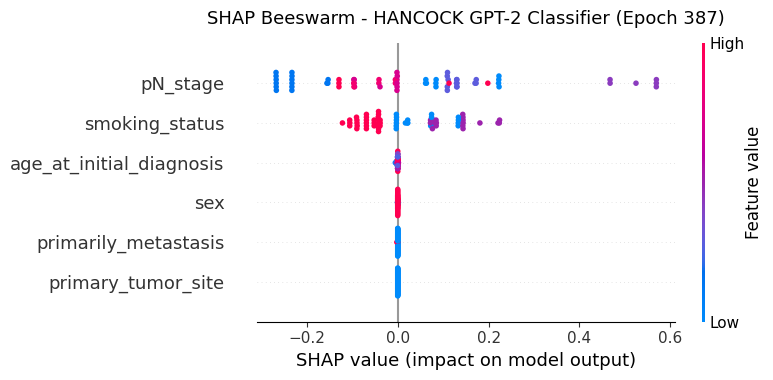


Calculating LIME explanation...


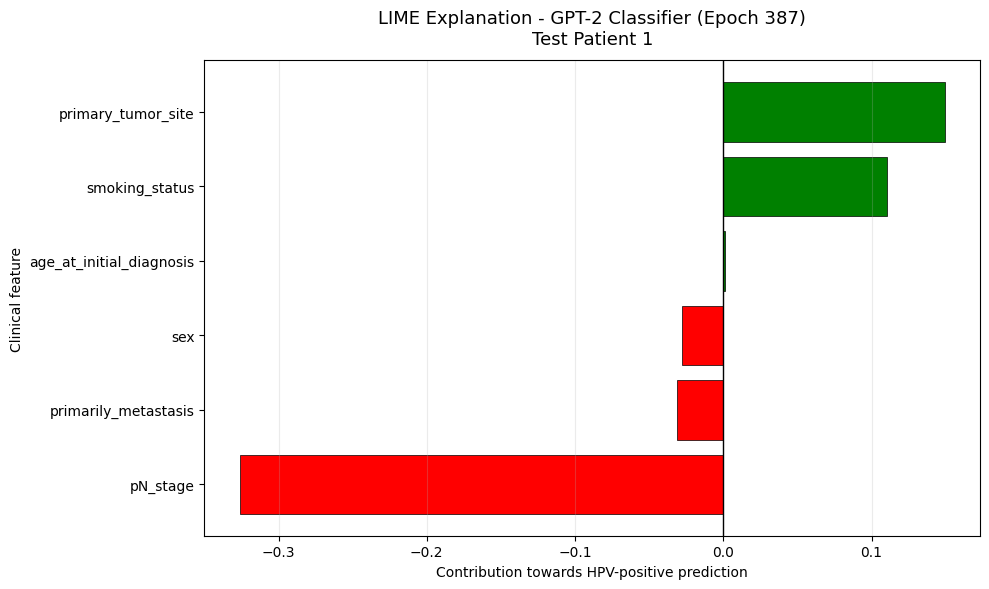


SHAP AND LIME FILES CREATED
/content/ROC_HANCOCK_GPT2_CLASSIFIER/GPT2_epoch387_SHAP_beeswarm.png
/content/ROC_HANCOCK_GPT2_CLASSIFIER/GPT2_epoch387_LIME.png
/content/ROC_HANCOCK_GPT2_CLASSIFIER/GPT2_epoch387_SHAP_values.csv
/content/ROC_HANCOCK_GPT2_CLASSIFIER/GPT2_epoch387_LIME_contributions.csv

ZIP file: /content/ROC_HANCOCK_GPT2_CLASSIFIER/GPT2_epoch387_SHAP_LIME_downloads.zip



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:

# ============================================================
# SHAP + LIME EXPLANATIONS
# HANCOCK GPT-2 CLASSIFIER - EPOCH 387
# Exactly six original clinical features
# Saves and downloads PNG files
# ============================================================

import os
import sys
import subprocess
import zipfile
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. INSTALL AND IMPORT SHAP / LIME
# ------------------------------------------------------------

try:
    import shap
    from lime.lime_tabular import LimeTabularExplainer
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "shap", "lime"
    ])
    import shap
    from lime.lime_tabular import LimeTabularExplainer

# ------------------------------------------------------------
# 2. CHECK REQUIRED NOTEBOOK VARIABLES
# ------------------------------------------------------------

required_variables = [
    "model", "tokenizer", "device", "test_df", "train_df",
    "patient_to_text", "features", "MAX_LENGTH"
]

missing = [v for v in required_variables if v not in globals()]
if missing:
    raise NameError(f"Missing notebook variables: {missing}")

features = [
    "age_at_initial_diagnosis",
    "sex",
    "smoking_status",
    "primary_tumor_site",
    "primarily_metastasis",
    "pN_stage"
]

assert len(features) == 6

# ------------------------------------------------------------
# 3. LOAD THE EPOCH 387 CHECKPOINT
# ------------------------------------------------------------

OUT_DIR = "/content/ROC_HANCOCK_GPT2_CLASSIFIER"
os.makedirs(OUT_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    OUT_DIR,
    "best_model_validation_balanced_accuracy.pth"
)

if not os.path.exists(checkpoint_path):
    raise FileNotFoundError(
        f"Checkpoint not found: {checkpoint_path}"
    )

state_dict = torch.load(checkpoint_path, map_location=device)
model.load_state_dict(state_dict)

model.to(device)
model.eval()

print("Loaded checkpoint:", checkpoint_path)
print("Using six features:", features)
print("Test patients:", len(test_df))

# ------------------------------------------------------------
# 4. PREPARE ORIGINAL CLINICAL FEATURES
#    Categorical values are coded only for SHAP/LIME input.
#    They are decoded back to their original values before
#    constructing the GPT-2 text prompts.
# ------------------------------------------------------------

train_features = train_df[features].copy().reset_index(drop=True)
test_features = test_df[features].copy().reset_index(drop=True)

categorical_features = features[1:]

category_levels = {}

for col in categorical_features:
    levels = sorted(
        set(train_features[col].astype(str))
        | set(test_features[col].astype(str))
    )
    category_levels[col] = levels

# Encode six original features into a numeric matrix.
def encode_features(data):
    encoded = np.zeros((len(data), 6), dtype=float)

    # Age remains continuous.
    encoded[:, 0] = pd.to_numeric(
        data["age_at_initial_diagnosis"], errors="coerce"
    ).fillna(
        pd.to_numeric(
            train_features["age_at_initial_diagnosis"],
            errors="coerce"
        ).median()
    ).to_numpy()

    # The other five features are categorical.
    for j, col in enumerate(categorical_features, start=1):
        mapping = {
            value: index
            for index, value in enumerate(category_levels[col])
        }
        encoded[:, j] = (
            data[col].astype(str).map(mapping).to_numpy()
        )

    return encoded


X_train_explain = encode_features(train_features)
X_test_explain = encode_features(test_features)

# Decode numeric representations back into original clinical values.
def decode_features(encoded_array):
    encoded_array = np.asarray(encoded_array)
    decoded = pd.DataFrame()

    decoded["age_at_initial_diagnosis"] = encoded_array[:, 0]

    for j, col in enumerate(categorical_features, start=1):
        levels = category_levels[col]
        indices = np.rint(encoded_array[:, j]).astype(int)
        indices = np.clip(indices, 0, len(levels) - 1)
        decoded[col] = [levels[i] for i in indices]

    return decoded[features]


# ------------------------------------------------------------
# 5. GPT-2 PREDICTION FUNCTION
#    Returns probability of HPV-positive (class 1).
# ------------------------------------------------------------

def predict_hpv_probabilities(encoded_array, batch_size=32):

    clinical_data = decode_features(encoded_array)

    prompts = [
        patient_to_text(row)
        for _, row in clinical_data.iterrows()
    ]

    all_probabilities = []

    model.eval()

    with torch.no_grad():
        for start in range(0, len(prompts), batch_size):

            batch_prompts = prompts[start:start + batch_size]

            tokens = tokenizer(
                batch_prompts,
                max_length=MAX_LENGTH,
                padding="max_length",
                truncation=True,
                return_tensors="pt"
            )

            input_ids = tokens["input_ids"].to(device)
            attention_mask = tokens["attention_mask"].to(device)

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            probabilities = torch.softmax(logits, dim=1)[:, 1]

            all_probabilities.extend(
                probabilities.detach().cpu().numpy()
            )

    return np.asarray(all_probabilities)


def predict_two_classes(encoded_array):
    positive_probability = predict_hpv_probabilities(encoded_array)
    negative_probability = 1.0 - positive_probability

    return np.column_stack([
        negative_probability,
        positive_probability
    ])


# Verify prediction function.
test_probabilities = predict_hpv_probabilities(X_test_explain)

print("\nPrediction check:")
print("Number of predictions:", len(test_probabilities))
print("First five HPV-positive probabilities:")
print(test_probabilities[:5])

# ------------------------------------------------------------
# 6. SHAP KERNEL EXPLAINER
#    One SHAP feature per original clinical feature.
# ------------------------------------------------------------

print("\nCalculating SHAP values. This may take some time...")

rng = np.random.default_rng(42)

background_size = min(20, len(X_train_explain))
background_indices = rng.choice(
    len(X_train_explain),
    size=background_size,
    replace=False
)

X_background = X_train_explain[background_indices]

shap_explainer = shap.KernelExplainer(
    predict_hpv_probabilities,
    X_background
)

shap_values = shap_explainer.shap_values(
    X_test_explain,
    nsamples=100
)

# Support different SHAP output formats.
if isinstance(shap_values, list):
    # For a two-class model, use class 1 (HPV positive).
    shap_positive = np.asarray(shap_values[0])
else:
    shap_array = np.asarray(shap_values)

    if shap_array.ndim == 3:
        if shap_array.shape[-1] == 2:
            shap_positive = shap_array[:, :, 1]
        elif shap_array.shape[0] == 2:
            shap_positive = shap_array[1]
        else:
            raise ValueError(
                f"Unexpected SHAP output shape: {shap_array.shape}"
            )
    else:
        shap_positive = shap_array

if shap_positive.shape != (len(X_test_explain), 6):
    raise ValueError(
        f"Expected SHAP shape {(len(X_test_explain), 6)}, "
        f"but received {shap_positive.shape}"
    )

# Create a beeswarm plot with exactly six features.
plt.figure(figsize=(10, 6))

shap.summary_plot(
    shap_positive,
    X_test_explain,
    feature_names=features,
    plot_type="dot",
    max_display=6,
    show=False
)

plt.title(
    "SHAP Beeswarm - HANCOCK GPT-2 Classifier (Epoch 387)",
    fontsize=13,
    pad=14
)
plt.tight_layout()

shap_png = os.path.join(
    OUT_DIR,
    "GPT2_epoch387_SHAP_beeswarm.png"
)

plt.savefig(
    shap_png,
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Save SHAP values as a CSV as well.
shap_df = pd.DataFrame(
    shap_positive,
    columns=features
)

shap_df.to_csv(
    os.path.join(OUT_DIR, "GPT2_epoch387_SHAP_values.csv"),
    index=False
)

# ------------------------------------------------------------
# 7. LIME EXPLAINER
#    Explain the first test patient by default.
#    One contribution per original clinical feature.
# ------------------------------------------------------------

print("\nCalculating LIME explanation...")

lime_explainer = LimeTabularExplainer(
    training_data=X_train_explain,
    feature_names=features,
    categorical_features=[1, 2, 3, 4, 5],
    categorical_names={
        j: category_levels[col]
        for j, col in enumerate(categorical_features, start=1)
    },
    class_names=["HPV Negative", "HPV Positive"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Select the first test patient.
# Change patient_index to explain another test patient.
patient_index = 0

lime_explanation = lime_explainer.explain_instance(
    data_row=X_test_explain[patient_index],
    predict_fn=predict_two_classes,
    labels=(1,),
    num_features=6,
    num_samples=1000
)

# Retrieve contributions by original feature index.
lime_map = lime_explanation.as_map()[1]

lime_contributions = np.zeros(6)

for feature_index, contribution in lime_map:
    lime_contributions[feature_index] = contribution

lime_df = pd.DataFrame({
    "Feature": features,
    "LIME_Contribution": lime_contributions
})

lime_df = lime_df.sort_values(
    "LIME_Contribution",
    ascending=True
)

# Green = pushes prediction towards HPV-positive.
# Red = pushes prediction away from HPV-positive.
bar_colours = [
    "green" if value > 0 else "red"
    for value in lime_df["LIME_Contribution"]
]

plt.figure(figsize=(10, 6))

plt.barh(
    lime_df["Feature"],
    lime_df["LIME_Contribution"],
    color=bar_colours,
    edgecolor="black",
    linewidth=0.5
)

plt.axvline(
    0,
    color="black",
    linewidth=1
)

plt.xlabel("Contribution towards HPV-positive prediction")
plt.ylabel("Clinical feature")

plt.title(
    f"LIME Explanation - GPT-2 Classifier (Epoch 387)\n"
    f"Test Patient {patient_index + 1}",
    fontsize=13,
    pad=12
)

plt.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()

lime_png = os.path.join(
    OUT_DIR,
    "GPT2_epoch387_LIME.png"
)

plt.savefig(
    lime_png,
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Save LIME contributions as CSV.
lime_df.to_csv(
    os.path.join(OUT_DIR, "GPT2_epoch387_LIME_contributions.csv"),
    index=False
)

# ------------------------------------------------------------
# 8. SAVE BOTH PNG FILES AND CSV FILES INTO A ZIP
# ------------------------------------------------------------

zip_path = os.path.join(
    OUT_DIR,
    "GPT2_epoch387_SHAP_LIME_downloads.zip"
)

files_to_zip = [
    shap_png,
    lime_png,
    os.path.join(OUT_DIR, "GPT2_epoch387_SHAP_values.csv"),
    os.path.join(OUT_DIR, "GPT2_epoch387_LIME_contributions.csv")
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for file_path in files_to_zip:
        zip_file.write(
            file_path,
            arcname=os.path.basename(file_path)
        )

print("\n======================================")
print("SHAP AND LIME FILES CREATED")
print("======================================")

for file_path in files_to_zip:
    print(file_path)

print("\nZIP file:", zip_path)

# ------------------------------------------------------------
# 9. DOWNLOAD FILES IN GOOGLE COLAB
# ------------------------------------------------------------

try:
    from google.colab import files

    print("\nDownloading ZIP file...")
    files.download(zip_path)

except ImportError:
    print(
        "\nNot running in Google Colab. "
        "The files have been saved in:",
        OUT_DIR
    )
